# 9 · Fine-tuning, LoRA, and preference learning

**Question.** How do we adapt an existing model, and whose preferences are represented?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/09-adaptation-alignment.ipynb)

Adaptation can change the conditioning information, some parameters, or all parameters. Preference learning adds another distinction: observations now describe comparisons between responses rather than necessarily providing a uniquely correct response. We will fit a low-rank update to a synthetic regression problem and then fit a small preference policy whose objective can be inspected directly.

**Prerequisites:** Chapters 2 and 6, matrix rank, and logistic likelihood. **Outcomes:** identify what is frozen; implement a low-rank update; interpret paired preference data; derive the role of a reference policy. These are small numerical experiments, not fine-tuning runs on a large pretrained language model.

## 9.1 · Choose the intervention to match the problem

| Method | What changes? | A natural use |
|:--|:--|:--|
| Prompting | Input context | Specify a task or output convention |
| Retrieval | Evidence supplied in context | Use a document collection that can be updated |
| Supervised fine-tuning | Model parameters | Learn behavior from input/response examples |
| LoRA | Selected low-rank parameter updates | Reduce the number of trainable parameters |
| Preference optimization | Parameters using comparisons | Favor responses according to observed preferences |

Supervised fine-tuning minimizes a response-token negative log likelihood conditional on the instruction. Often the instruction tokens are excluded from that loss. Data provenance, duplicates, and separation by task or document matter: a large collection of nearly identical instructions is not equivalent to a large collection of independent tasks.

## 9.2 · Low-rank adaptation as a constrained update

Use row-vector inputs and a weight matrix $W_0\in\mathbb R^{d_{in}\times d_{out}}$. We freeze $W_0$ and fit

$$
W=W_0+sAB,\quad A\in\mathbb R^{d_{in}\times r},\quad
B\in\mathbb R^{r\times d_{out}}.
$$

The update has rank at most $r$ and $r(d_{in}+d_{out})$ trainable entries, compared with $d_{in}d_{out}$ for a full update. The scale $s$ is explicit; conventions often express it as a hyperparameter divided by rank. The restriction can reduce variance or prevent fitting a necessary high-rank change. It is not guaranteed to improve accuracy.

Initialize one factor randomly and the other at zero. If **both** factors start at zero, gradients of their product are zero and the update cannot begin learning.

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(9)
din, dout, rank = 12, 8, 2
W0 = torch.randn(din, dout) * 0.2
true_update = (torch.randn(din, rank) @ torch.randn(rank, dout)) * 0.15
X = torch.randn(250, din)
Y = X @ (W0 + true_update) + 0.1 * torch.randn(250, dout)
Xtr, Xte, Ytr, Yte = X[:50], X[50:], Y[:50], Y[50:]

def fit_update(low_rank):
    if low_rank:
        A = nn.Parameter(torch.randn(din, rank) * 0.03)
        B = nn.Parameter(torch.zeros(rank, dout))
        parameters = [A, B]
        update = lambda: A @ B
    else:
        delta = nn.Parameter(torch.zeros(din, dout))
        parameters = [delta]
        update = lambda: delta
    optimizer = torch.optim.Adam(parameters, lr=0.03)
    for _ in range(450):
        optimizer.zero_grad()
        loss = ((Xtr @ (W0 + update()) - Ytr)**2).mean()
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        result = update().clone()
        train_mse = ((Xtr @ (W0+result)-Ytr)**2).mean().item()
        test_mse = ((Xte @ (W0+result)-Yte)**2).mean().item()
    return result, train_mse, test_mse

full, full_train, full_test = fit_update(False)
low, low_train, low_test = fit_update(True)
print('Trainable entries: full', din*dout, 'low-rank', rank*(din+dout))
print('Full update train/test MSE:', round(full_train, 4), round(full_test, 4))
print('Low-rank update train/test MSE:', round(low_train, 4), round(low_test, 4))
assert not W0.requires_grad
assert torch.linalg.matrix_rank(low, atol=1e-4) <= rank

Trainable entries: full 96 low-rank 40
Full update train/test MSE: 0.0082 0.0135
Low-rank update train/test MSE: 0.0093 0.0117


The true update was deliberately chosen to have rank two. This favors the low-rank assumption and must be disclosed when interpreting results. To test robustness, replace it with a full-rank matrix, vary training size, and repeat the entire comparison. In transformers, low-rank updates may be attached to selected projection matrices; choosing their locations is another modeling decision.

## 9.3 · Inspect the fitted update, not only parameter counts

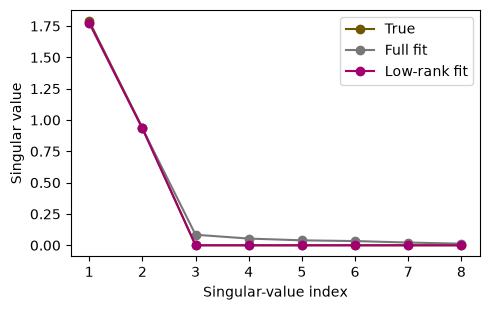

In [2]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for name, matrix, color in [('True', true_update, '#705600'),
                             ('Full fit', full, '#777777'),
                             ('Low-rank fit', low, '#a2006e')]:
    singular = torch.linalg.svdvals(matrix).numpy()
    ax.plot(range(1, len(singular)+1), singular, 'o-', label=name, color=color)
ax.set(xlabel='Singular-value index', ylabel='Singular value')
ax.legend()
plt.tight_layout()
plt.show()

A low-rank parameterization is a restriction on an update in parameter space, not a claim that all task information is low-dimensional. Parameter count alone also does not determine training memory: activations, optimizer state, precision, and frozen-weight storage still matter.

## 9.4 · Preference observations and Bradley–Terry probabilities

For a prompt $x$, suppose a latent utility function $r(x,y)$ determines pairwise preference probabilities:

$$
P(y_a\succ y_b\mid x)=\sigma\{r(x,y_a)-r(x,y_b)\}.
$$

Adding a constant to all utilities for a prompt leaves these probabilities unchanged. The model describes a population of preference observations, not an objective notion of truth. Annotator selection, ambiguous instructions, response length, presentation order, and disagreement all affect the labels.

A common RLHF formulation fits a reward model from comparisons and then optimizes expected reward while penalizing KL divergence from a reference policy. For a fixed prompt and unrestricted policy, maximizing $\mathbb E_\pi r-\beta\operatorname{KL}(\pi\Vert\pi_{ref})$ yields $\pi^*(y)\propto\pi_{ref}(y)e^{r(y)/\beta}$, assuming the relevant support and normalizer conditions.

## 9.5 · A tiny direct-preference objective

Substituting the log policy ratio into the paired-comparison likelihood gives the DPO loss for a preferred response $y_w$ and a dispreferred response $y_l$:

$$
-\log\sigma\left(\beta\left[
\log\frac{\pi_\theta(y_w\mid x)}{\pi_{ref}(y_w\mid x)}
-\log\frac{\pi_\theta(y_l\mid x)}{\pi_{ref}(y_l\mid x)}\right]\right).
$$

We use one prompt with three possible responses, a uniform reference, and simulated noisy preferences. For language models, each response log probability is a sum of token log probabilities, with careful handling of prompt masking and sequence length. The discrete example makes the reference term and preference direction easy to verify.

In [3]:
rng = np.random.default_rng(90)
utilities = np.array([1.2, 0.3, -0.8])
pairs = np.array([rng.choice(3, size=2, replace=False) for _ in range(500)])
p_first = 1 / (1 + np.exp(-(utilities[pairs[:, 0]]-utilities[pairs[:, 1]])))
first_wins = rng.random(len(pairs)) < p_first
winners = torch.tensor(np.where(first_wins, pairs[:, 0], pairs[:, 1]))
losers = torch.tensor(np.where(first_wins, pairs[:, 1], pairs[:, 0]))
train_ids, test_ids = np.arange(400), np.arange(400, 500)
reference = torch.full((3,), 1/3)
policy_logits = nn.Parameter(torch.zeros(3))
optimizer = torch.optim.Adam([policy_logits], lr=0.03)
beta_preference = 0.7
for _ in range(300):
    optimizer.zero_grad()
    log_ratio = torch.log_softmax(policy_logits, dim=0) - reference.log()
    margin = beta_preference * (log_ratio[winners[train_ids]]-log_ratio[losers[train_ids]])
    loss = -nn.functional.logsigmoid(margin).mean()
    loss.backward()
    optimizer.step()
with torch.no_grad():
    policy = torch.softmax(policy_logits, dim=0)
    ratio = policy.log()-reference.log()
    test_margin = beta_preference*(ratio[winners[test_ids]]-ratio[losers[test_ids]])
    heldout_loss = -nn.functional.logsigmoid(test_margin).mean().item()
print('Reference probabilities:', reference.numpy().round(3))
print('Fitted probabilities:', policy.numpy().round(3))
print('Held-out preference log loss:', round(heldout_loss, 3))
print('Equal-preference log loss:', round(np.log(2), 3))

Reference probabilities: [0.333 0.333 0.333]
Fitted probabilities: [0.72  0.216 0.063]
Held-out preference log loss: 0.486
Equal-preference log loss: 0.693


This test holds out comparison draws, not new prompts. It evaluates the same three-response preference problem under additional label noise. It cannot establish generalization to new tasks or factual correctness. The reference policy has positive probability on every response, so its log ratios are defined.

## 9.6 · Design an adaptation evaluation

Keep separate evaluations for task quality, instruction compliance, factual support, and resource cost. Use a baseline with the same retrieval access and decoding budget. If preference tuning improves a judge score, inspect whether response length or style changed in a way the judge rewards independently of correctness.

Record the base model, adaptation data, frozen parameters, trainable parameters, optimizer, checkpoint rule, and evaluation split. Prevent task-family leakage where paraphrases of the same underlying question appear in both training and testing. A comparison against an untuned baseline is informative only if the baseline receives an appropriate prompt and comparable evidence.

## 9.7 · Exercises and worked solutions

1. **Parameter budget:** for a $1024\times1024$ update with rank eight, how many entries are trained? **Solution:** $8(1024+1024)=16,384$, versus $1,048,576$ for a full update. This counts update parameters, not the entire model's stored weights.
2. **Initialization:** derive $\nabla_A L$ and $\nabla_B L$ when $\Delta=AB$. **Solution:** if $G=\nabla_\Delta L$, the gradients are $GB^\top$ and $A^\top G$. Both vanish if both factors are zero.
3. **Identifiability:** does paired-comparison data identify an absolute utility level? **Solution:** no. It identifies differences under the model, since adding a common constant leaves all comparison probabilities unchanged.
4. **DPO direction:** if policy and reference initially agree, what is each margin? **Solution:** zero. The loss is $\log2$. Updating increases the preferred response's log ratio relative to the dispreferred response, subject to shared parameters and conflicting observations.
5. **Scope:** why might a rank-two update fail even with excellent optimization? **Solution:** the necessary parameter change may have higher rank or may be needed in layers that were not adapted. More optimization cannot remove a restriction imposed by the model class.

## 9.8 · Reading and transition

[LoRA](https://arxiv.org/abs/2106.09685) develops low-rank parameter updates for large models. [DPO](https://arxiv.org/abs/2305.18290) connects preference likelihoods with a reference-policy formulation. Next, [Chapter 10](https://chikuang.github.io/teaching/genai/chapters/10-rag.html) changes the evidence available at inference time while leaving model weights fixed.